In [ ]:
import os
import pickle
import gzip
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from PIL import Image
from tqdm.notebook import tqdm
from nltk.translate.bleu_score import corpus_bleu, SmoothingFunction
from tensorflow.keras.applications.vgg16 import VGG16, preprocess_input
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.utils import to_categorical, plot_model
from tensorflow.keras.layers import Input, Dense, LSTM, Embedding, Dropout, add

HEllo people

In [2]:
BASE_DIR = ''
WORKING_DIR = '' 


In [3]:
# load vgg16 model
model = VGG16()
# restructure the model
model = Model(inputs=model.inputs, outputs=model.layers[-2].output)
# summarize
print(model.summary())

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 25088)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc1 (Dense)                     │ (None, 4096)           │   102,764,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ fc2 (Dense)                     │ (None, 4096)           │    16,781,312 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 134,260,544 (512.16 MB)

 Trainable params: 134,260,544 (512.16 MB)

 Non-trainable params: 0 (0.00 B)

None


In [4]:
# Extract VGG16 features for every image - or load them if already cached.
#
# VGG16 is frozen, so its output for a given image never changes. This is the
# slowest step in the notebook, so the result is cached to features.pkl:
#   cache hit  -> ~2 seconds
#   extraction -> ~8 minutes (batched, see below)
FEATURES_PATH = os.path.join(WORKING_DIR, 'features.pkl')
FEATURES_GZ = FEATURES_PATH + '.gz'
BATCH = 32   # images per predict call

if os.path.exists(FEATURES_PATH):
    with open(FEATURES_PATH, 'rb') as f:
        features = pickle.load(f)
    print(f'loaded {len(features)} cached features from {FEATURES_PATH}')
elif os.path.exists(FEATURES_GZ):
    # features.pkl.gz is the copy committed to git. The raw pickle is 127 MB,
    # which is over GitHub's 100 MB per-file hard limit; gzipped it is ~45 MB.
    with gzip.open(FEATURES_GZ, 'rb') as f:
        features = pickle.load(f)
    print(f'loaded {len(features)} cached features from {FEATURES_GZ}')
else:
    # Build the feature extractor only when it is actually needed. Note this is
    # named `vgg`, NOT `model` - overwriting `model` here would clobber the
    # captioning model built later in the notebook.
    vgg = VGG16()
    vgg = Model(inputs=vgg.inputs, outputs=vgg.layers[-2].output)

    directory = os.path.join(BASE_DIR, 'Images')
    img_names = sorted(os.listdir(directory))
    features = {}

    # Batching is a 5x speedup. A predict call on 32 images costs barely more
    # than on 1, because per-call overhead dominates the actual computation:
    # measured 310 ms/image one at a time vs 60 ms/image in batches of 32.
    for i in tqdm(range(0, len(img_names), BATCH)):
        chunk = img_names[i:i + BATCH]
        batch = np.array([
            img_to_array(load_img(os.path.join(directory, n), target_size=(224, 224)))
            for n in chunk
        ])
        batch = preprocess_input(batch)
        vecs = vgg.predict(batch, verbose=0)
        for name, vec in zip(chunk, vecs):
            # Keep the (1, 4096) shape the rest of the notebook expects
            features[name.split('.')[0]] = vec.reshape((1, 4096))

    # Written only after the loop completes, so an interrupted run can never
    # leave a partial features.pkl behind.
    with open(FEATURES_PATH, 'wb') as f:
        pickle.dump(features, f)
    print(f'extracted and cached {len(features)} features')

loaded 8091 cached features from features.pkl


In [5]:
# Saving is handled by the cell above (it writes features.pkl after extracting).
# Re-dumping here would overwrite a good 133 MB cache with whatever is currently
# in `features`, so it is intentionally disabled.
#
# pickle.dump(features, open(os.path.join(WORKING_DIR, 'features.pkl'), 'wb'))
print(f'{len(features)} features in memory')

8091 features in memory


In [6]:
# load features from pickle
with open(os.path.join(WORKING_DIR, 'features.pkl'), 'rb') as f:
    features = pickle.load(f)

In [7]:
with open(os.path.join(BASE_DIR, 'captions.txt'), 'r') as f:
    next(f)
    captions_doc = f.read()

In [8]:
# create mapping of image to captions
mapping = {}
# process lines
for line in captions_doc.split('\n'):
    # split the line by comma(,)
    tokens = line.split(',')
    if len(line) < 2:
        continue
    image_id, caption = tokens[0], tokens[1:]
    # remove extension from image ID
    image_id = image_id.split('.')[0]
    # convert caption list to string
    caption = " ".join(caption)
    # create list if needed
    if image_id not in mapping:
        mapping[image_id] = []
    # store the caption
    mapping[image_id].append(caption)

In [9]:
len(mapping)


8091

In [10]:
def clean(mapping):
    for key, captions in mapping.items():
        for i in range(len(captions)):
        # take one caption at a time
          caption = captions[i]
        # preprocessing steps
        # convert to lowercase
          caption = caption.lower()
        # delete digits, special chars, etc.,
          caption = caption.replace('[^A-Za-z]', '')
        # delete additional spaces
          caption = caption.replace('\s+', ' ')
        # add start and end tags to the caption
          caption = 'startseq ' + " ".join([word for word in         caption.split() if len(word)>1]) + ' endseq'
          captions[i] = caption

In [11]:
# before preprocess of text
mapping['1000268201_693b08cb0e']

['A child in a pink dress is climbing up a set of stairs in an entry way .',
 'A girl going into a wooden building .',
 'A little girl climbing into a wooden playhouse .',
 'A little girl climbing the stairs to her playhouse .',
 'A little girl in a pink dress going into a wooden cabin .']

In [12]:
# preprocess the text
clean(mapping)


In [13]:
# after preprocess of text
mapping['1000268201_693b08cb0e']

['startseq child in pink dress is climbing up set of stairs in an entry way endseq',
 'startseq girl going into wooden building endseq',
 'startseq little girl climbing into wooden playhouse endseq',
 'startseq little girl climbing the stairs to her playhouse endseq',
 'startseq little girl in pink dress going into wooden cabin endseq']

In [14]:
all_captions = []
for key in mapping:
    for caption in mapping[key]:
        all_captions.append(caption)

In [15]:
len(all_captions)


40455

In [16]:
all_captions[:10]


['startseq child in pink dress is climbing up set of stairs in an entry way endseq',
 'startseq girl going into wooden building endseq',
 'startseq little girl climbing into wooden playhouse endseq',
 'startseq little girl climbing the stairs to her playhouse endseq',
 'startseq little girl in pink dress going into wooden cabin endseq',
 'startseq black dog and spotted dog are fighting endseq',
 'startseq black dog and tri-colored dog playing with each other on the road endseq',
 'startseq black dog and white dog with brown spots are staring at each other in the street endseq',
 'startseq two dogs of different breeds looking at each other on the road endseq',
 'startseq two dogs on pavement moving toward each other endseq']

In [17]:
# tokenize the text
tokenizer = Tokenizer()
tokenizer.fit_on_texts(all_captions)
vocab_size = len(tokenizer.word_index) + 1

In [18]:
vocab_size


8485

In [19]:
# get maximum length of the caption available
max_length = max(len(caption.split()) for caption in all_captions)
max_length

35

In [ ]:
# Split the dataset into training, validation and testing sets

image_ids = list(mapping.keys())

# 80% training, 10% validation, 10% testing
train_end = int(len(image_ids) * 0.80)
val_end = int(len(image_ids) * 0.90)

train = image_ids[:train_end]
val = image_ids[train_end:val_end]
test = image_ids[val_end:]

print("Dataset split")
print("-" * 35)
print(f"Training images:   {len(train)} ({len(train)/len(image_ids):.1%})")
print(f"Validation images: {len(val)} ({len(val)/len(image_ids):.1%})")
print(f"Testing images:    {len(test)} ({len(test)/len(image_ids):.1%})")
print(f"Total images:      {len(image_ids)}")


Dataset split
-----------------------------------
Training images:   6472 (80.0%)
Validation images: 809 (10.0%)
Testing images:    810 (10.0%)
Total images:      8091


In [21]:
# startseq girl going into wooden building endseq
#        X                   y
# startseq                   girl
# startseq girl              going
# startseq girl going        into
# ...........
# startseq girl going into wooden building      endseq

In [22]:
# create data generator to get data in batch (avoids session crash)
def data_generator(data_keys, mapping, features, tokenizer, max_length, vocab_size, batch_size):
    # loop over images
    X1, X2, y = list(), list(), list()
    n = 0
    while 1:
        for key in data_keys:
            n += 1
            captions = mapping[key]
            # process each caption
            for caption in captions:
                # encode the sequence
                seq = tokenizer.texts_to_sequences([caption])[0]
                # split the sequence into X, y pairs
                for i in range(1, len(seq)):
                      # split into input and output pairs
                      in_seq, out_seq = seq[:i], seq[i]
                    # pad input sequence
                      in_seq = pad_sequences([in_seq], maxlen=max_length)[0]
                    # encode output sequence
                      out_seq = to_categorical([out_seq],
                      num_classes=vocab_size)[0]
                    # store the sequences
                      X1.append(features[key][0])
                      X2.append(in_seq)
                      y.append(out_seq)
            if n == batch_size:
                  X1, X2, y = np.array(X1), np.array(X2), np.array(y)
                  yield (X1, X2), y
                  X1, X2, y = list(), list(), list()
                  n = 0

In [23]:
# encoder model
# image feature layers
inputs1 = Input(shape=(4096,))
fe1 = Dropout(0.4)(inputs1)
fe2 = Dense(256, activation='relu')(fe1)
# sequence feature layers
inputs2 = Input(shape=(max_length,))
se1 = Embedding(vocab_size, 256, mask_zero=True)(inputs2)
se2 = Dropout(0.4)(se1)
se3 = LSTM(256)(se2)

# decoder model
decoder1 = add([fe2, se3])
decoder2 = Dense(256, activation='relu')(decoder1)
outputs = Dense(vocab_size, activation='softmax')(decoder2)

model = Model(inputs=[inputs1, inputs2], outputs=outputs)
model.compile(loss='categorical_crossentropy', optimizer='adam')

# plot the model
plot_model(model, show_shapes=True)

You must install graphviz (see instructions at https://graphviz.gitlab.io/download/) for `plot_model` to work.



Epoch 1/20


c:\Users\legos\AppData\Local\Programs\Python\Python311\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a generator. The generator is expected to yield already-shuffled data.
  self.data_adapter = data_adapters.get_data_adapter(


202/202 ━━━━━━━━━━━━━━━━━━━━ 178s 875ms/step - loss: 5.2468 - val_loss: 4.4384

Epoch 2/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 186s 922ms/step - loss: 4.0078 - val_loss: 3.9989

Epoch 3/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 197s 975ms/step - loss: 3.5701 - val_loss: 3.8950

Epoch 4/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 199s 985ms/step - loss: 3.3028 - val_loss: 3.8900

Epoch 5/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 202s 998ms/step - loss: 3.1060 - val_loss: 3.9209

Epoch 6/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 198s 980ms/step - loss: 2.9538 - val_loss: 3.9795

Epoch 7/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 197s 976ms/step - loss: 2.8355 - val_loss: 4.0273

Epoch 8/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 202s 1s/step - loss: 2.7398 - val_loss: 4.0469

Epoch 9/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 201s 996ms/step - loss: 2.6526 - val_loss: 4.0841

Epoch 10/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 209s 1s/step - loss: 2.5822 - val_loss: 4.1454

Epoch 11/20
202/202 ━━━━━━━━━━━━━━━━━━━━ 206s 1s/step - loss: 2.5213 - val_loss: 4.1807

Epoch 12/20
202/2

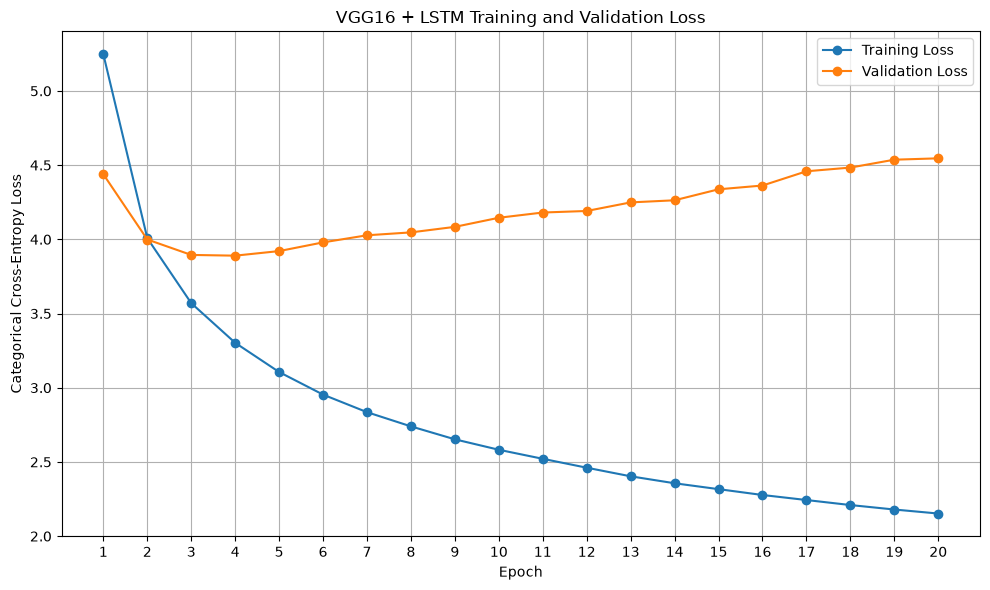

In [24]:
# train the model
epochs = 20
batch_size = 32
steps = len(train) // batch_size
val_steps = len(val) // batch_size

# Store loss values for every epoch
training_loss = []
validation_loss = []

for i in range(epochs):

    print(f"\nEpoch {i + 1}/{epochs}")

    # Create training generator
    train_generator = data_generator(train, mapping, features, tokenizer, max_length, vocab_size, batch_size)

    # Create validation generator
    val_generator = data_generator(val, mapping, features, tokenizer, max_length, vocab_size, batch_size)

    # Train for one epoch and evaluate on validation data
    history = model.fit(
        train_generator,
        epochs=1,
        steps_per_epoch=steps,
        validation_data=val_generator,
        validation_steps=val_steps,
        verbose=1
    )

    # Save the loss values
    training_loss.append(history.history["loss"][-1])
    validation_loss.append(history.history["val_loss"][-1])

# Plot training and validation loss
plt.figure(figsize=(10, 6))

plt.plot(
    range(1, epochs + 1),
    training_loss,
    marker="o",
    label="Training Loss"
)

plt.plot(
    range(1, epochs + 1),
    validation_loss,
    marker="o",
    label="Validation Loss"
)

plt.title("VGG16 + LSTM Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Categorical Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [25]:
# Save the trained model so a fresh kernel can skip the ~1 hour training run.
# .keras is the current Keras 3 format; .h5 is the legacy one.
MODEL_PATH = os.path.join(WORKING_DIR, 'best_model.keras')

model.save(MODEL_PATH)
print('saved', MODEL_PATH)

# To RESUME from a previously saved model instead of re-training, comment out
# the two lines above and uncomment the line below:
# model = load_model(MODEL_PATH)

saved best_model.keras


In [26]:
#saves Training and Validation loss


loss_df = pd.DataFrame({
    "Epoch": range(1, epochs + 1),
    "Training Loss": training_loss,
    "Validation Loss": validation_loss
})

loss_df.to_csv("training_validation_loss.csv", index=False)

print(loss_df)
print("\nSaved to training_validation_loss.csv")

    Epoch  Training Loss  Validation Loss
0       1       5.246826         4.438380
1       2       4.007823         3.998935
2       3       3.570083         3.895016
3       4       3.302831         3.890049
4       5       3.105955         3.920910
5       6       2.953796         3.979485
6       7       2.835522         4.027336
7       8       2.739786         4.046874
8       9       2.652568         4.084137
9      10       2.582226         4.145421
10     11       2.521289         4.180729
11     12       2.461384         4.191126
12     13       2.403404         4.248942
13     14       2.356533         4.263179
14     15       2.316883         4.337149
15     16       2.277487         4.362641
16     17       2.243598         4.458532
17     18       2.209793         4.483580
18     19       2.179623         4.536669
19     20       2.152575         4.545845

Saved to training_validation_loss.csv


In [27]:
def idx_to_word(integer, tokenizer):
    for word, index in tokenizer.word_index.items():
        if index == integer:
          return word
    return None

In [28]:
# generate caption for an image
def predict_caption(model, image, tokenizer, max_length):
    # add start tag for generation process
    in_text = 'startseq'
    # iterate over the max length of sequence
    for i in range(max_length):
        # encode input sequence
        sequence = tokenizer.texts_to_sequences([in_text])[0]
        # pad the sequence
        sequence = pad_sequences([sequence], max_length)
        # predict next word
        yhat = model.predict([image, sequence], verbose=0)
        # get index with high probability
        yhat = np.argmax(yhat)
        # convert index to word
        word = idx_to_word(yhat, tokenizer)
        # stop if word not found
        if word is None:
            break
        # append word as input for generating next word
        in_text += " " + word
        # stop if we reach end tag
        if word == 'endseq':
            break
    return in_text

In [ ]:
# Remove startseq/endseq tokens from references and predictions
references_clean = [
    [
        [w for w in caption if w not in ("startseq", "endseq")]
        for caption in image_captions
    ]
    for image_captions in actual
]

predictions_clean = [
    [w for w in caption if w not in ("startseq", "endseq")]
    for caption in predicted
]

smooth = SmoothingFunction().method1

bleu_scores = {
    "BLEU-1": corpus_bleu(
        references_clean, predictions_clean,
        weights=(1, 0, 0, 0),
        smoothing_function=smooth
    ),
    "BLEU-2": corpus_bleu(
        references_clean, predictions_clean,
        weights=(0.5, 0.5, 0, 0),
        smoothing_function=smooth
    ),
    "BLEU-3": corpus_bleu(
        references_clean, predictions_clean,
        weights=(1/3, 1/3, 1/3, 0),
        smoothing_function=smooth
    ),
    "BLEU-4": corpus_bleu(
        references_clean, predictions_clean,
        weights=(0.25, 0.25, 0.25, 0.25),
        smoothing_function=smooth
    )
}

for metric, score in bleu_scores.items():
    print(f"{metric}: {score:.4f}")

BLEU-1: 0.4000
BLEU-2: 0.2697
BLEU-3: 0.1564
BLEU-4: 0.0699


In [ ]:
def predict_caption_beam(
    model, image, tokenizer, max_length, beam_width=3
):
    start = "startseq"
    end = "endseq"

    # Each candidate contains (word sequence, cumulative log probability)
    sequences = [([start], 0.0)]

    for _ in range(max_length):
        all_candidates = []

        for sequence, score in sequences:
            if sequence[-1] == end:
                all_candidates.append((sequence, score))
                continue

            encoded = tokenizer.texts_to_sequences(
                [" ".join(sequence)]
            )[0]

            padded = pad_sequences(
                [encoded], maxlen=max_length
            )

            probabilities = model.predict(
                [image, padded], verbose=0
            )[0]

            # Keep the top candidate words for this sequence
            top_indices = np.argsort(probabilities)[-beam_width:]

            for idx in top_indices:
                word = idx_to_word(idx, tokenizer)

                if word is None:
                    continue

                probability = max(float(probabilities[idx]), 1e-12)
                candidate = (
                    sequence + [word],
                    score + np.log(probability)
                )
                all_candidates.append(candidate)

        if not all_candidates:
            break

        sequences = sorted(
            all_candidates,
            key=lambda item: item[1] / max(len(item[0]) - 1, 1),
            reverse=True
        )[:beam_width]

        if all(seq[-1] == end for seq, _ in sequences):
            break

    best_sequence = max(
        sequences,
        key=lambda item: item[1] / max(len(item[0]) - 1, 1)
    )[0]

    return " ".join(best_sequence)

In [ ]:
beam_width = 3
greedy_refs, greedy_preds = [], []
beam_refs, beam_preds = [], []

for image_id in tqdm(test):
    refs = [
        caption.replace("startseq", "").replace("endseq", "").split()
        for caption in mapping[image_id]
    ]

    greedy_caption = predict_caption(
        model, features[image_id], tokenizer, max_length
    )

    beam_caption = predict_caption_beam(
        model, features[image_id], tokenizer, max_length,
        beam_width=beam_width
    )

    greedy_tokens = [
        w for w in greedy_caption.split()
        if w not in ("startseq", "endseq")
    ]

    beam_tokens = [
        w for w in beam_caption.split()
        if w not in ("startseq", "endseq")
    ]

    greedy_refs.append(refs)
    greedy_preds.append(greedy_tokens)
    beam_refs.append(refs)
    beam_preds.append(beam_tokens)

smooth = SmoothingFunction().method1

for n in range(1, 5):
    weights = tuple(
        [1/n] * n + [0] * (4-n)
    )

    greedy_score = corpus_bleu(
        greedy_refs, greedy_preds,
        weights=weights, smoothing_function=smooth
    )

    beam_score = corpus_bleu(
        beam_refs, beam_preds,
        weights=weights, smoothing_function=smooth
    )

    print(
        f"BLEU-{n}: Greedy = {greedy_score:.4f}, "
        f"Beam Search = {beam_score:.4f}"
    )

  0%|          | 0/810 [00:00<?, ?it/s]

BLEU-1: Greedy = 0.4240, Beam Search = 0.4252
BLEU-2: Greedy = 0.2477, Beam Search = 0.2613
BLEU-3: Greedy = 0.1435, Beam Search = 0.1594
BLEU-4: Greedy = 0.0809, Beam Search = 0.0944


In [ ]:
def generate_caption(image_name):
    # load the image
    # image_name = "1001773457_577c3a7d70.jpg"
    image_id = image_name.split('.')[0]
    img_path = os.path.join(BASE_DIR, "Images", image_name)
    image = Image.open(img_path)
    captions = mapping[image_id]
    print('---------------------Actual---------------------')
    for caption in captions:
        print(caption)
    # predict the caption
    y_pred = predict_caption(model, features[image_id], tokenizer, max_length)
    print('--------------------Predicted--------------------')
    print(y_pred)
    plt.imshow(image)

---------------------Actual---------------------
startseq black dog and spotted dog are fighting endseq
startseq black dog and tri-colored dog playing with each other on the road endseq
startseq black dog and white dog with brown spots are staring at each other in the street endseq
startseq two dogs of different breeds looking at each other on the road endseq
startseq two dogs on pavement moving toward each other endseq
--------------------Predicted--------------------
startseq two dogs are playing with each other on the ground endseq


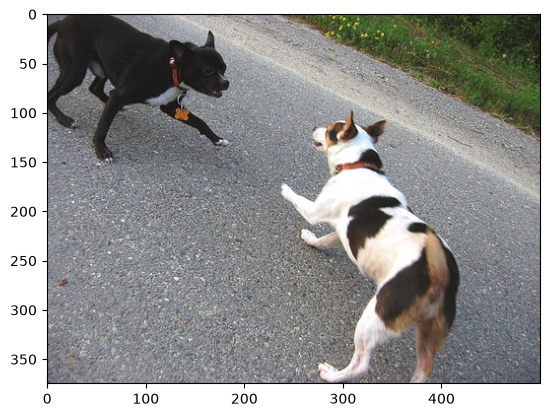

In [35]:
generate_caption("1001773457_577c3a7d70.jpg")


---------------------Actual---------------------
startseq little girl covered in paint sits in front of painted rainbow with her hands in bowl endseq
startseq little girl is sitting in front of large painted rainbow endseq
startseq small girl in the grass plays with fingerpaints in front of white canvas with rainbow on it endseq
startseq there is girl with pigtails sitting in front of rainbow painting endseq
startseq young girl with pigtails painting outside in the grass endseq
--------------------Predicted--------------------
startseq girl in pink dress is holding onto the rainbow and painting from blanket endseq


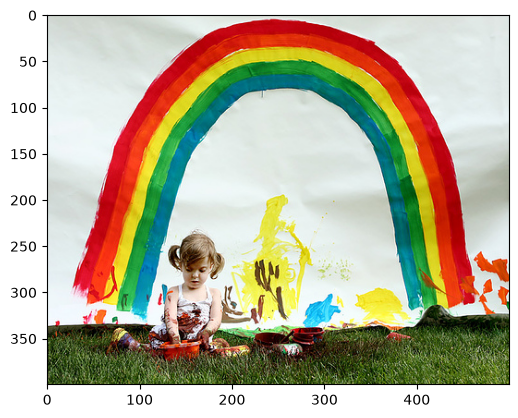

In [51]:
generate_caption("1002674143_1b742ab4b8.jpg")


---------------------Actual---------------------
startseq man in hat is displaying pictures next to skier in blue hat endseq
startseq man skis past another man displaying paintings in the snow endseq
startseq person wearing skis looking at framed pictures set up in the snow endseq
startseq skier looks at framed pictures in the snow next to trees endseq
startseq man on skis looking at artwork for sale in the snow endseq
--------------------Predicted--------------------
startseq two people are standing in the snow endseq


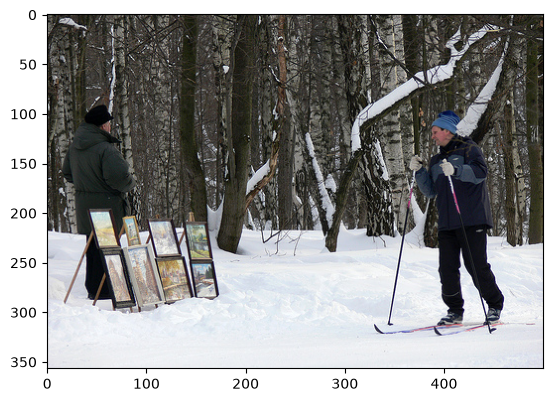

In [37]:
generate_caption("101669240_b2d3e7f17b.jpg")


In [38]:
vgg_model = VGG16()
# restructure the model
vgg_model = Model(inputs=vgg_model.inputs,outputs=vgg_model.layers[-2].output)

startseq two dogs are playing in the grass endseq


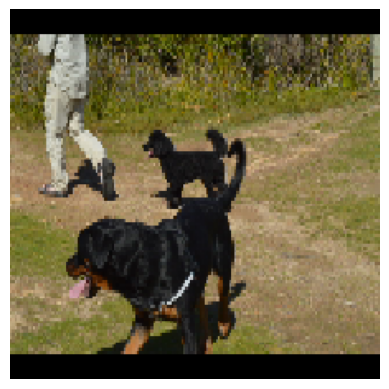

In [52]:
# Caption an image of your choice (i.e. one that is NOT part of Flickr8k).
#
# The tutorial this notebook derives from used a local file called 'download.jpg'
# that was never committed, which is why this cell raised FileNotFoundError.
# Drop any .jpg into the project root and point IMAGE_PATH at it. If the file is
# missing we fall back to a held-out test image so the cell always runs.
IMAGE_PATH = 'DSC_0875.NEF'

if not os.path.exists(IMAGE_PATH):
    # test[] holds ids the model never trained on - change the index to see others
    fallback_id = test[0]
    IMAGE_PATH = os.path.join(BASE_DIR, 'Images', fallback_id + '.jpg')
    print(f"'download.jpg' not found - using held-out test image {fallback_id}.jpg")

# load the image and show it
image = load_img(IMAGE_PATH, target_size=(224, 224))
plt.imshow(image)
plt.axis('off')

# convert image pixels to numpy array
image = img_to_array(image)
# reshape data for the model: (1, 224, 224, 3)
image = image.reshape((1, image.shape[0], image.shape[1], image.shape[2]))
# preprocess the image the way VGG16 expects (channel-wise mean subtraction)
image = preprocess_input(image)

# extract the 4096-d feature vector with the same frozen encoder used for the cache
feature = vgg_model.predict(image, verbose=0)

# decode a caption from that feature vector using the trained captioning model
print(predict_caption(model, feature, tokenizer, max_length))